# Chapter 89: Norms, Identity, Social Interaction, and Multipliers

This notebook reruns four of the chapter's hypothetical cases: a peer multiplier on a cycling subsidy, a threshold cascade that one boundary stalls, a neighborhood tipped by a few exits, and a buyer who values exclusivity. A few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def social_multiplier(beta, gamma, rounds=6):
    """Equilibrium change beta / (1 - gamma) and the first feedback rounds beta gamma^k.

    Principle: social-multiplier (chapter 89). Book: beta = 6, gamma = 0.4 gives 10 (6 direct, 4
    feedback, rounds 6, 2.4, 0.96); gamma = 0 gives 6; gamma = -0.2 gives 6 / 1.2 = 5. Returns None
    for total and multiplier when gamma >= 1 (no stable linear equilibrium).
    """
    stable = gamma < 1
    total = beta / (1 - gamma) if stable else None
    return {"total": total, "multiplier": (1 / (1 - gamma)) if stable else None, "direct": beta,
            "feedback": (total - beta) if stable else None, "stable": stable,
            "rounds": [beta * gamma ** k for k in range(rounds)]}


def threshold_cascade(thresholds, seed=0):
    """Granovetter cascade: worker i joins once the visible count (active + seed) reaches theta_i.

    Principle: threshold-model-of-collective-behavior (chapter 89). Book: (0, 1, ..., 9) reaches 10;
    (0, 1, 2, 4, 4, 5, ..., 9) stalls at 3; one visible seed revives it to 10.
    Returns final active count and the count after each round (index 0 = before round 1).
    """
    active = [False] * len(thresholds)
    history = [0]
    while True:
        count = sum(active) + seed
        new = [a or (t <= count) for a, t in zip(active, thresholds)]
        if new == active:
            break
        active = new
        history.append(sum(active))
    return {"final": sum(active), "history": history, "active": active}


def schelling_cascade(nA, nB, groups, exits):
    """Tipping with A-share thresholds; external exits come from the least sensitive group (last).

    Principle: schelling-segregation-tipping (chapter 89). Book: 52 A, 48 B, groups
    [(20, 0.50), (32, 0.40)], 5 exits: 47/95 = 49.5%, then 27/75 = 36%, then 0 A households.
    groups: list of (count, threshold). Each wave every group whose threshold exceeds the current
    share leaves together. Returns final A, waves [(A, share)], vacancies out of nA + nB homes.
    """
    counts = [c for c, _ in groups]
    counts[-1] -= exits
    waves = []
    while True:
        a = sum(counts)
        share = a / (a + nB) if a + nB > 0 else 0.0
        waves.append((a, share))
        leave = [i for i, (c, (_, t)) in enumerate(zip(counts, groups)) if c > 0 and share < t]
        if not leave:
            break
        for i in leave:
            counts[i] = 0
    a = sum(counts)
    return {"final_A": a, "waves": waves, "vacancies": nA + nB - a - nB, "counts": counts}


def network_wtp(base, slope, N):
    """Willingness to pay W = base + slope N (slope < 0 snob, > 0 bandwagon).

    Principle: snob-effect (chapter 89). Book: W = 300 - 2N gives 220 at N = 40 and 160 at N = 70;
    the bandwagon buyer has W = 140 + 2N.
    """
    return base + slope * N


plt.rcParams.update(HOUSE_RC)


behavioral = SimpleNamespace(social_multiplier=social_multiplier, threshold_cascade=threshold_cascade, schelling_cascade=schelling_cascade, network_wtp=network_wtp)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'social-multiplier': {'beta': 6,
                       'gamma': 0.4,
                       'total': 10,
                       'feedback': 4,
                       'rounds': (6, 2.4, 0.96),
                       'gamma_neg': -0.2,
                       'total_neg': 5},
 'threshold-model-of-collective-behavior': {'base': (0, 1, 2, 3, 4, 5, 6, 7, 8, 9),
                                            'changed': (0, 1, 2, 4, 4, 5, 6, 7, 8, 9),
                                            'final_base': 10,
                                            'final_changed': 3,
                                            'final_seed': 10},
 'schelling-segregation-tipping': {'nA': 52,
                                   'nB': 48,
                                   'groups': ((20, 0.5), (32, 0.4)),
                                   'exits': 5,
                                   'share1': 0.49473684210526314,
                                   'share2': 0.36,
                                   'final_A': 0,
                                   'vacancies': 52,
                                   't_low': 0.45},
 'snob-effect': {'base': 300,
                 'slope': -2,
                 'N': 40,
                 'price': 180,
                 'W': 220,
                 'surplus': 40,
                 'N_big': 70,
                 'W_big': 160,
                 'bandwagon_base': 140,
                 'bandwagon_slope': 2},
 'constructed': {'social-multiplier': {'beta': [3, 9], 'gamma': [0.6]},
                 'threshold-model-of-collective-behavior': {'t4': [5], 'seed': [2]},
                 'schelling-segregation-tipping': {'exits': [3, 7]},
                 'snob-effect': {'N': [55]}}}


def multiplier_picture(beta=6, gamma=0.4):
    r = behavioral.social_multiplier(beta, gamma)
    total, mult = r["total"], r["multiplier"]
    rounds = r["rounds"]
    cum = np.cumsum(rounds)
    fig, ax = new_figure()
    ks = np.arange(1, len(rounds) + 1)
    ax.bar(ks, rounds, color=[PALETTE["teal"]] + [PALETTE["gold"]] * (len(rounds) - 1), width=0.6)
    ax.plot(ks, cum, color=PALETTE["navy"], marker="o", linewidth=2)
    hline(ax, total, f"equilibrium total {num(total)}", col="terracotta", x_frac=0.35)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    label(ax, ks[-1], cum[-1], "running total", col="navy", dx=-6, dy=-10, ha="right", va="top")
    lo = min(0, min(rounds))
    ax.set_ylim(lo - 1 if lo < 0 else 0, max(total, max(cum)) * 1.22)
    ax.set_xticks(ks, ["direct"] + [f"round {k}" for k in ks[1:]])
    ax.set_xlabel("Adjustment round")
    ax.set_ylabel("Change in adoption (points)")
    fb = total - beta
    den = f"1 + {num(-gamma)}" if gamma < 0 else f"1 - {num(gamma)}"
    if gamma > 0:
        verdict = f"peers amplify the subsidy: {num(fb)} points come through feedback"
    elif gamma < 0:
        verdict = f"interaction dampens the subsidy: feedback subtracts {num(-fb)} points"
    else:
        verdict = "there is no feedback, so the total equals the direct effect"
    metrics = {"Equilibrium change": f"{num(total)} points", "Direct effect": f"{num(beta, 0)} points",
               "Feedback": f"{num(fb)} points", "Multiplier 1 / (1 - gamma)": num(mult)}
    steps = [f"Rounds: {num(beta, 0)}, {num(beta, 0)} x {num(gamma)} = {num(rounds[1])}, "
             f"{num(rounds[1])} x {num(gamma)} = {num(rounds[2])}, ...",
             f"Total = {num(beta, 0)} / ({den}) = {num(beta, 0)} / {num(1 - gamma)} = {num(total)}",
             f"Feedback = {num(total)} - {num(beta, 0)} = {num(fb)}"]
    interp = (f"A direct effect of {num(beta, 0)} points with peer feedback {num(gamma)} settles at "
              f"{num(beta, 0)} / ({den}) = {num(total)} points: {verdict}.")
    alt = (f"Bars of each adjustment round starting at {num(beta, 0)} points, a running total line, and the "
           f"equilibrium total of {num(total)} points.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cascade_picture(t4=4, seed=0):
    th = [0, 1, 2, t4, 4, 5, 6, 7, 8, 9]
    r = behavioral.threshold_cascade(th, seed)
    final, act = r["final"], r["active"]
    fig, ax = new_figure()
    xs = np.arange(1, 11)
    for x, t, a in zip(xs, th, act):
        ax.scatter([x], [t], s=150, color=PALETTE["teal"] if a else "white", edgecolors=PALETTE["teal"],
                   linewidths=2, zorder=4)
    hline(ax, final + seed, col="terracotta")
    label(ax, 0.5, 12.6, f"visible count at the end: {final} + {seed} = {final + seed}", col="terracotta", dx=0,
          dy=0, va="center")
    ax.set_xlim(0.3, 10.7)
    ax.set_ylim(-1, 13.5)
    ax.set_xticks(xs)
    ax.set_xlabel("Worker")
    ax.set_ylabel("Threshold (active workers needed)")
    label(ax, 10.5, 11.4, "filled = joined, open = waits", dx=0, dy=0, ha="right", va="center", box=False)
    stalled = final < 10
    if stalled:
        nxt = min(t for t, a in zip(th, act) if not a)
        verdict = (f"the cascade stalls at {final} of 10: the next threshold is {nxt}, above the visible count of "
                   f"{final} + {seed} = {final + seed}")
    else:
        verdict = "every threshold is met in turn, so all 10 join"
    metrics = {"Final participation": f"{final} of 10", "Visible seeds": str(seed),
               "Thresholds": ", ".join(str(t) for t in th)}
    steps = [f"Thresholds: ({', '.join(str(t) for t in th)}); seeds = {seed}",
             "Active counts by round: " + ", ".join(str(h) for h in r["history"]),
             f"Result: {verdict}"]
    interp = (f"With the fourth threshold at {t4} and {seed} visible seed{'s' if seed != 1 else ''}, {verdict}. "
              f"The final visible count is {final} + {seed} = {final + seed}.")
    alt = (f"Ten workers plotted by threshold; {final} are filled as joined. Thresholds "
           f"{', '.join(str(t) for t in th)} with {seed} seeds.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tipping_picture(exits=5, t1=0.50):
    b = BV["schelling-segregation-tipping"]
    groups = [(20, t1), (32, 0.40)]
    r = behavioral.schelling_cascade(b["nA"], b["nB"], groups, exits)
    waves = r["waves"]
    fig, ax = new_figure()
    xs = np.arange(len(waves) + 1)
    shares = [0.52] + [s for _, s in waves]
    ax.plot(xs, shares, color=PALETTE["navy"], marker="o", linewidth=2.2)
    for x, s in zip(xs, shares):
        label(ax, x, s, pct(s), dx=8, dy=4)
    hline(ax, t1, f"20 stay above {pct(t1, 0)}", col="terracotta", x_frac=0.7, va="bottom")
    hline(ax, 0.40, "32 stay above 40%", col="gold", x_frac=0.7, va="top")
    ax.set_xlim(-0.3, max(len(waves), 2) * 1.0 + 3.0)
    ax.set_ylim(-0.05, 0.68)
    ax.set_xticks(xs, ["start"] + ["after exits"] + [f"wave {k}" for k in range(1, len(waves))])
    ax.set_xlabel("Stage")
    ax.set_ylabel("A share of occupied homes")
    a1 = waves[0][0]
    final = r["final_A"]
    metrics = {"A share after exits": pct(waves[0][1]), "Final A households": str(final),
               "Vacancies": str(r["vacancies"])}
    steps = [f"After {exits} exits: {a1} / ({a1} + 48) = {a1} / {a1 + 48} = {pct(waves[0][1])}"]
    for k in range(1, len(waves)):
        a, s = waves[k]
        steps.append(f"Wave {k}: {a} / ({a} + 48) = {pct(s)}")
    if final == 0:
        verdict = "the neighborhood tips: every A household leaves, leaving 48 B households and 52 vacancies"
    else:
        verdict = f"the cascade stops with {final} A households"
    steps.append(f"Result: {verdict}")
    interp = (f"{exits} external exits leave {a1} A households among {a1 + 48} occupied homes, a share of "
              f"{a1} / {a1 + 48} = {pct(waves[0][1])} against the sensitive group's {pct(t1, 0)} boundary, so "
              f"{verdict}.")
    alt = (f"A share of occupied homes by stage, starting at 52% and falling to {pct(waves[-1][1])}, with threshold "
           f"lines at {pct(t1, 0)} and 40%.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def snob_picture(n=40, price=180):
    b = BV["snob-effect"]
    W = behavioral.network_wtp(b["base"], b["slope"], n)
    Wb = behavioral.network_wtp(b["bandwagon_base"], b["bandwagon_slope"], n)
    surplus = W - price
    grid = np.linspace(0, 100, 101)
    fig, ax = new_figure()
    ax.plot(grid, b["base"] + b["slope"] * grid, color=PALETTE["teal"], linewidth=2.2)
    ax.plot(grid, b["bandwagon_base"] + b["bandwagon_slope"] * grid, color=PALETTE["grey"], linewidth=1.8,
            linestyle="dashed")
    label(ax, 8, 300 - 16, "snob buyer W = 300 - 2N", col="teal", dx=0, dy=6)
    label(ax, 96, 140 + 192, "bandwagon W = 140 + 2N", col="grey", dx=0, dy=-8, ha="right", va="top")
    hline(ax, price, f"price {money(price, 0)}", col="terracotta", x_frac=0.02, va="bottom")
    mark(ax, n, W, f"W = {money(W, 0)}", col="navy", dx=8, dy=6)
    ax.set_xlim(0, 100)
    ax.set_ylim(80, 360)
    ax.set_xlabel("Expected other owners N")
    ax.set_ylabel("Willingness to pay ($)")
    if surplus > 0:
        verdict = f"Lena buys with surplus {money(surplus, 0)}"
    elif surplus < 0:
        verdict = f"Lena declines: price exceeds her willingness to pay by {money(-surplus, 0)}"
    else:
        verdict = "Lena is indifferent: price equals willingness to pay"
    metrics = {"Willingness to pay W": money(W, 0), "Surplus W - price": money(surplus, 0),
               "Buys": "Yes" if surplus > 0 else ("Indifferent (tie)" if surplus == 0 else "No"),
               "Bandwagon buyer's W": money(Wb, 0)}
    steps = [f"W = 300 - 2 x {n} = {num(W, 0)}", f"Surplus = {num(W, 0)} - {price} = {num(surplus, 0)}",
             f"Bandwagon buyer: 140 + 2 x {n} = {num(Wb, 0)}", f"Result: {verdict}"]
    interp = (f"With {n} other expected owners, Lena's willingness to pay is 300 - 2 x {n} = {num(W, 0)} dollars "
              f"against a price of {price} dollars, so {verdict}. A bandwagon buyer values the same watch at "
              f"140 + 2 x {n} = {num(Wb, 0)} dollars.")
    alt = (f"Willingness to pay falls with expected owners for the snob buyer and rises for the bandwagon buyer; "
           f"at N = {n} the snob buyer's W is {money(W, 0)} against a price line at {money(price, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Social multiplier: how peers multiply a subsidy

The subsidy raises adoption 6 points directly; each point of peer adoption adds 0.4 more.

$$\frac{d\bar y}{dx}=\frac{\beta}{1-\gamma}, \qquad \frac{6}{1-0.4}=10$$

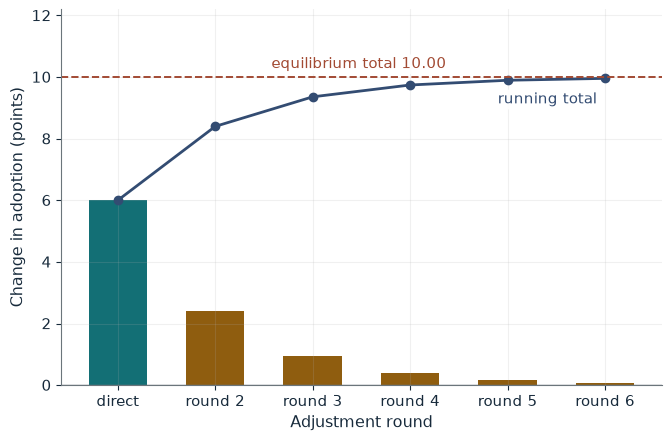

Equilibrium change          10.00 points
Direct effect               6 points
Feedback                    4.00 points
Multiplier 1 / (1 - gamma)  1.67

Worked steps:
  1. Rounds: 6, 6 x 0.40 = 2.40, 2.40 x 0.40 = 0.96, ...
  2. Total = 6 / (1 - 0.40) = 6 / 0.60 = 10.00
  3. Feedback = 10.00 - 6 = 4.00

A direct effect of 6 points with peer feedback 0.40 settles at 6 / (1 - 0.40) = 10.00 points: peers amplify the subsidy: 4.00 points come through feedback.


In [2]:
show(multiplier_picture(beta=6, gamma=0.4))

Change one input, `gamma`, and hold the others at the book's values:

In [3]:
sweep(multiplier_picture, 'gamma', [-0.2, 0, 0.4, 0.6], {'beta': 6}, ['Equilibrium change', 'Feedback'])

gamma | Equilibrium change | Feedback
-0.2 | 5.00 points | -1.00 points
0 | 6.00 points | 0.00 points
0.4 | 10.00 points | 4.00 points
0.6 | 15.00 points | 9.00 points


Six direct points become ten with feedback 0.4, stay six without interaction, and shrink to five when crowding makes gamma = -0.2.

## 2. Threshold model: one threshold stops a cascade

Ten workers join once the visible count reaches their thresholds.

$$(0,1,2,3,4,5,6,7,8,9) \qquad (0,1,2,4,4,5,6,7,8,9)$$

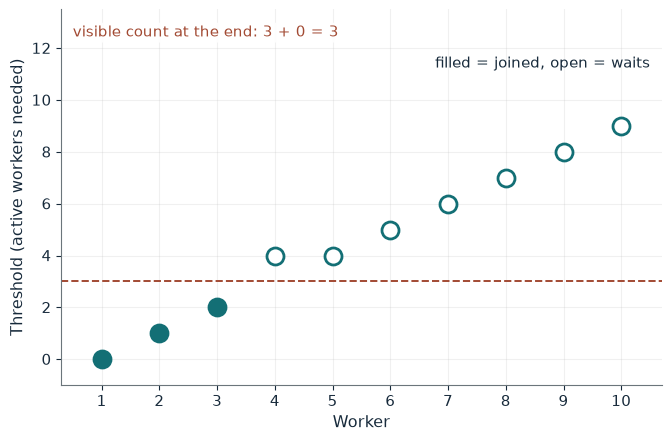

Final participation  3 of 10
Visible seeds        0
Thresholds           0, 1, 2, 4, 4, 5, 6, 7, 8, 9

Worked steps:
  1. Thresholds: (0, 1, 2, 4, 4, 5, 6, 7, 8, 9); seeds = 0
  2. Active counts by round: 0, 1, 2, 3
  3. Result: the cascade stalls at 3 of 10: the next threshold is 4, above the visible count of 3 + 0 = 3

With the fourth threshold at 4 and 0 visible seeds, the cascade stalls at 3 of 10: the next threshold is 4, above the visible count of 3 + 0 = 3. The final visible count is 3 + 0 = 3.


In [4]:
show(cascade_picture(t4=4, seed=0))

Change one input, `seed`, and hold the others at the book's values:

In [5]:
sweep(cascade_picture, 'seed', [0, 1, 2], {'t4': 4}, ['Final participation'])

seed | Final participation
0 | 3 of 10
1 | 10 of 10
2 | 10 of 10


Changing one threshold from 3 to 4 stalls the cascade at 3; one visible seed restarts it to 10.

## 3. Schelling tipping: five exits that tip a neighborhood

52 A and 48 B households; 20 A need a 50 percent A share and 32 accept 40 percent.

$$s_A=\frac{47}{95}\approx49.5\%, \qquad \frac{27}{75}=36\%$$

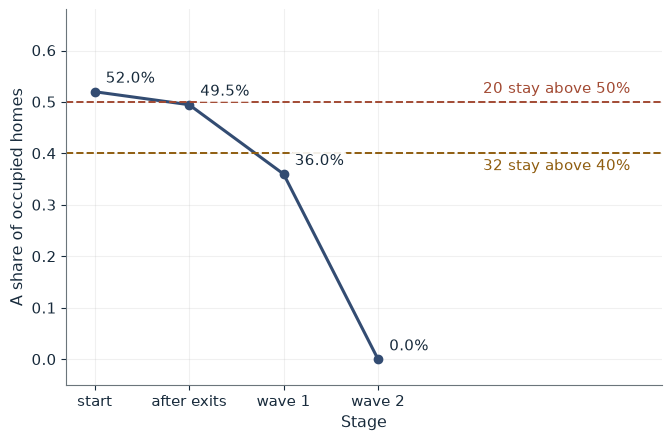

A share after exits  49.5%
Final A households   0
Vacancies            52

Worked steps:
  1. After 5 exits: 47 / (47 + 48) = 47 / 95 = 49.5%
  2. Wave 1: 27 / (27 + 48) = 36.0%
  3. Wave 2: 0 / (0 + 48) = 0.0%
  4. Result: the neighborhood tips: every A household leaves, leaving 48 B households and 52 vacancies

5 external exits leave 47 A households among 95 occupied homes, a share of 47 / 95 = 49.5% against the sensitive group's 50% boundary, so the neighborhood tips: every A household leaves, leaving 48 B households and 52 vacancies.


In [6]:
show(tipping_picture(exits=5, t1=0.50))

Change one input, `exits`, and hold the others at the book's values:

In [7]:
sweep(tipping_picture, 'exits', [3, 5, 7], {'t1': 0.5}, ['A share after exits', 'Final A households'])

exits | A share after exits | Final A households
3 | 50.5% | 49
5 | 49.5% | 0
7 | 48.4% | 0


Three exits leave 50.5 percent and nothing happens; five or seven push the share below 50 percent and every A household leaves.

## 4. Snob effect: exclusivity and willingness to pay

Lena's willingness to pay falls with the number of other owners.

$$W=300-2N$$

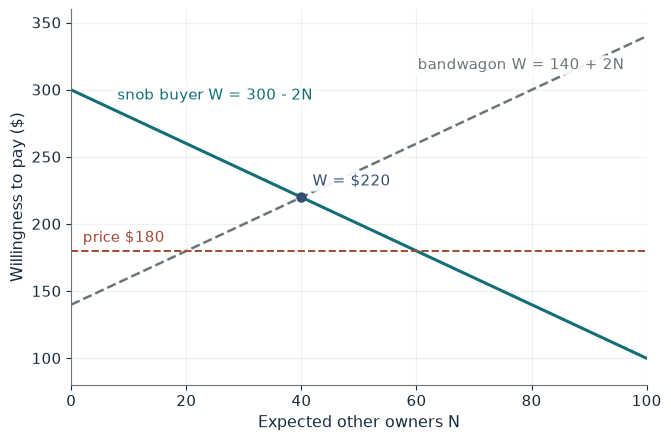

Willingness to pay W  $220
Surplus W - price     $40
Buys                  Yes
Bandwagon buyer's W   $220

Worked steps:
  1. W = 300 - 2 x 40 = 220
  2. Surplus = 220 - 180 = 40
  3. Bandwagon buyer: 140 + 2 x 40 = 220
  4. Result: Lena buys with surplus $40

With 40 other expected owners, Lena's willingness to pay is 300 - 2 x 40 = 220 dollars against a price of 180 dollars, so Lena buys with surplus $40. A bandwagon buyer values the same watch at 140 + 2 x 40 = 220 dollars.


In [8]:
show(snob_picture(n=40, price=180))

Change one input, `n`, and hold the others at the book's values:

In [9]:
sweep(snob_picture, 'n', [40, 55, 70], {'price': 180}, ['Willingness to pay W', 'Surplus W - price', 'Buys'])

n | Willingness to pay W | Surplus W - price | Buys
40 | $220 | $40 | Yes
55 | $190 | $10 | Yes
70 | $160 | -$20 | No


At N = 40 she buys with \$40 surplus; at N = 70 her willingness to pay is \$160 and she declines.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

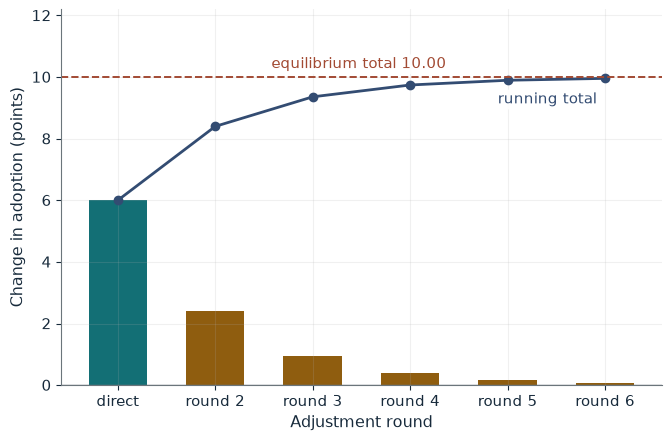

Equilibrium change          10.00 points
Direct effect               6 points
Feedback                    4.00 points
Multiplier 1 / (1 - gamma)  1.67

Worked steps:
  1. Rounds: 6, 6 x 0.40 = 2.40, 2.40 x 0.40 = 0.96, ...
  2. Total = 6 / (1 - 0.40) = 6 / 0.60 = 10.00
  3. Feedback = 10.00 - 6 = 4.00

A direct effect of 6 points with peer feedback 0.40 settles at 6 / (1 - 0.40) = 10.00 points: peers amplify the subsidy: 4.00 points come through feedback.


In [10]:
show(multiplier_picture(beta=6, gamma=0.4))

## Practice

**1.** With beta = 3 and gamma = 0.6, what is the equilibrium change?

<details><summary>Answer</summary>

3 / 0.4 = 7.5 points.

</details>

**2.** With 3 exits and the 50 percent threshold, what is the A share?

<details><summary>Answer</summary>

49 / 97 = 50.5%, so no one else leaves.

</details>

**3.** At N = 70 and price \$150, does Lena buy?

<details><summary>Answer</summary>

W = 160 > 150, so yes, with \$10 surplus.

</details>